# Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Download dataset from Kaggle

In [2]:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "data.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "uciml/breast-cancer-wisconsin-data",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

C:\Users\Miguel Estrada\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_2124\991810060.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


# Load & Explore Data

In [3]:
#display dataframe
df.head(3)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN


In [4]:
#count of rows and columns
df.shape

(569, 33)

In [5]:
#count number of null(empty) values
df.isna().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [6]:
# Drop the column with null values
df.dropna(axis=1, inplace=True)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [7]:
# count of rows and columns
df.shape

(569, 32)

In [8]:
#Get count of number of M or B cells in diagnosis
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

# Label Encoding

In [9]:
#Get Datatypes of each column in our dataset
df.dtypes

id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [10]:
# Encode diagnosis values: B (benign) = 0, M (malignant) = 1
labelencoder = LabelEncoder()
df['diagnosis'] = labelencoder.fit_transform(df['diagnosis'])

print(dict(zip(labelencoder.classes_, labelencoder.transform(labelencoder.classes_))))

{'B': np.int64(0), 'M': np.int64(1)}


In [11]:
#display df
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


#### Analysis

In [12]:
df_clean = df.drop(columns=["id"]).copy()
df_clean["diagnosis_label"] = df_clean["diagnosis"].map({
    0: "Benign (B)",
    1: "Malignant (M)",
})
df_clean.head(3)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_label
0,1,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant (M)
1,1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant (M)
2,1,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant (M)


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_2124\2308764154.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_2124\2308764154.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_2124\2308764154.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_2124\2308764154.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.1

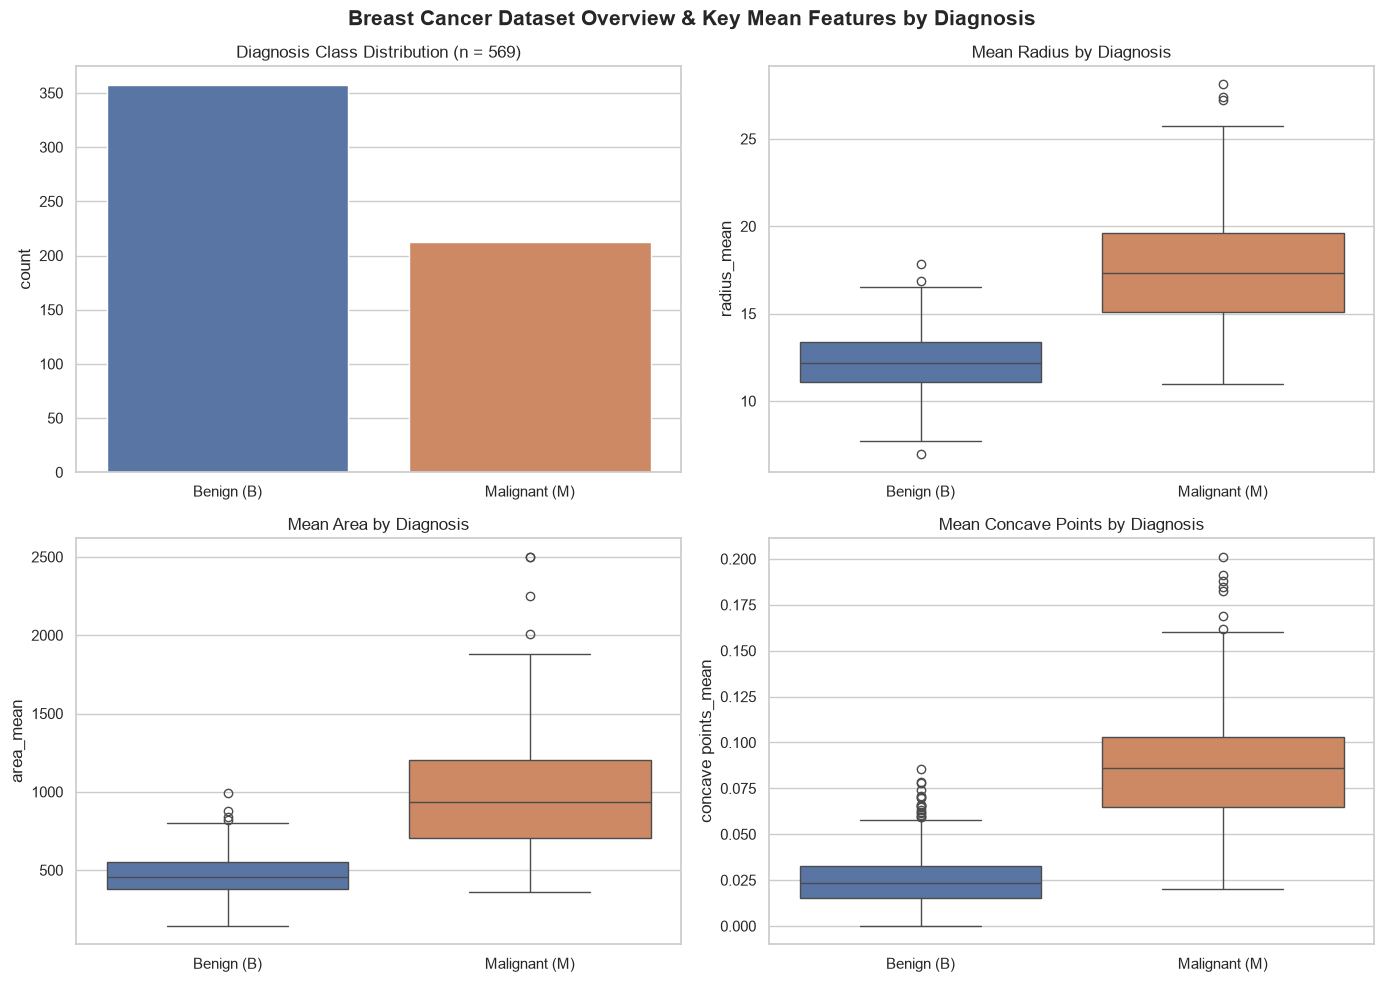

In [13]:
sns.set_theme(style="whitegrid", palette="muted")

order_labels = ["Benign (B)", "Malignant (M)"]
palette_map = {"Benign (B)": "#4C72B0", "Malignant (M)": "#DD8452"}

# 2. Diagnosis countplot + key feature boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Breast Cancer Dataset Overview & Key Mean Features by Diagnosis",
    fontsize=15,
    fontweight="bold",
)

sns.countplot(
    data=df_clean,
    x="diagnosis_label",
    order=order_labels,
    palette=palette_map,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Diagnosis Class Distribution (n = 569)")
axes[0, 0].set_xlabel("")

sns.boxplot(
    data=df_clean,
    x="diagnosis_label",
    y="radius_mean",
    order=order_labels,
    palette=palette_map,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Mean Radius by Diagnosis")
axes[0, 1].set_xlabel("")

sns.boxplot(
    data=df_clean,
    x="diagnosis_label",
    y="area_mean",
    order=order_labels,
    palette=palette_map,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Mean Area by Diagnosis")
axes[1, 0].set_xlabel("")

sns.boxplot(
    data=df_clean,
    x="diagnosis_label",
    y="concave points_mean",
    order=order_labels,
    palette=palette_map,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Mean Concave Points by Diagnosis")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()


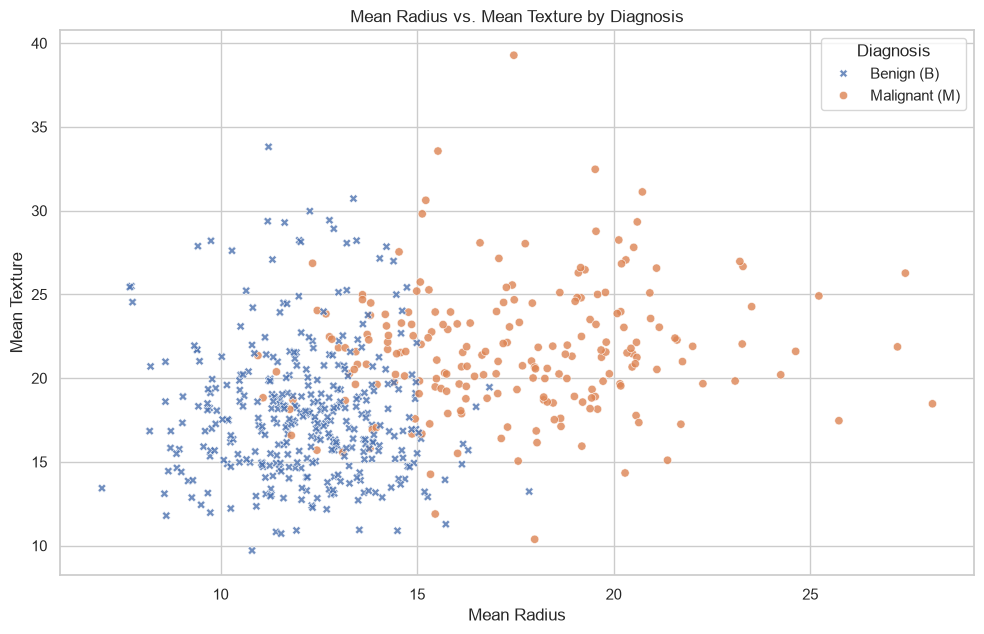

In [14]:
# 3. Scatterplot of radius_mean vs texture_mean
plt.figure(figsize=(10, 6.5))
sns.scatterplot(
    data=df_clean,
    x="radius_mean",
    y="texture_mean",
    hue="diagnosis_label",
    style="diagnosis_label",
    hue_order=order_labels,
    palette=palette_map,
    alpha=0.8,
)
plt.title("Mean Radius vs. Mean Texture by Diagnosis")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

# Split Dataset & Feature Scaling

In [15]:
# Separate predictive features (X) from the target (Y)
feature_names = df.columns[2:]
X = df[feature_names].values
Y = df['diagnosis'].values.astype(int)

In [16]:
# Reproducible, stratified 75/25 train-test split
x_train, x_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

In [17]:
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

#print data
y_train_smote

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,

# Build a Logistic Regression Model

In [18]:
# Train XGBClassifier
classifier = XGBClassifier(max_iter=1000, random_state=42)
classifier.fit(x_train_smote, y_train_smote)

C:\Users\Miguel Estrada\AppData\Roaming\Python\Python314\site-packages\xgboost\training.py:200: UserWarning: [18:46:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
#make use of trained model to make predictions on test data
predictions = classifier.predict(x_test)

# Performance Evaluation

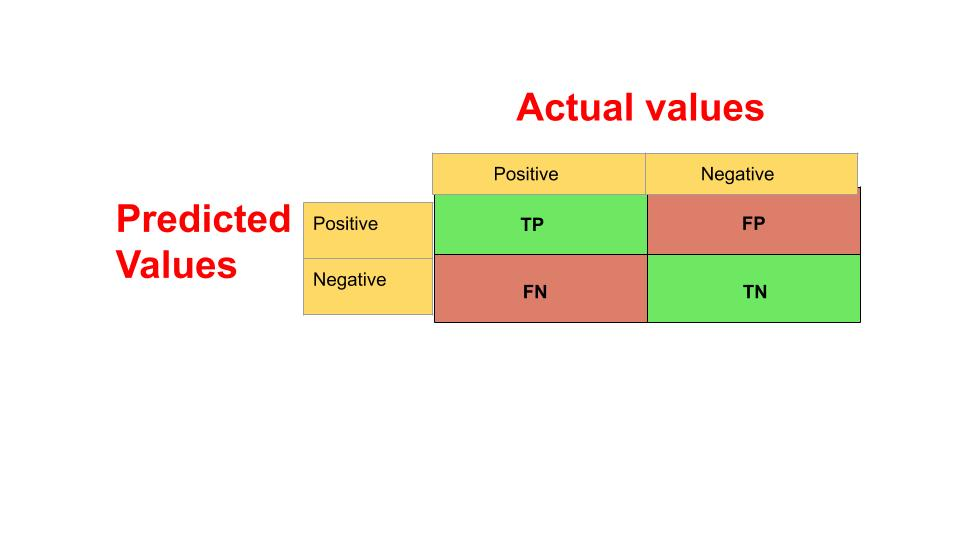

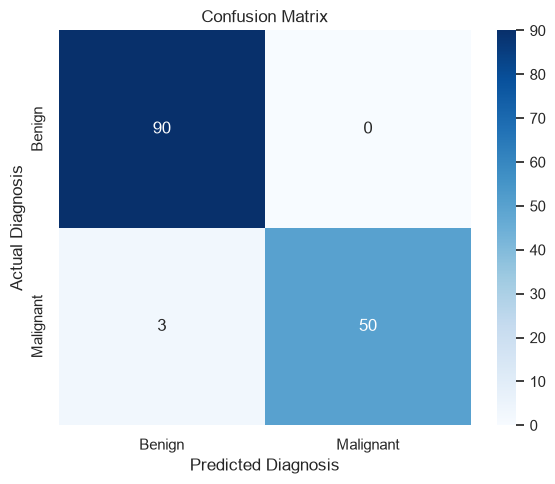

In [20]:
# Plot the confusion matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.tight_layout()
plt.show()

In [21]:
# Evaluate model performance
print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, classifier.predict_proba(x_test)[:, 1]):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=['Benign', 'Malignant']
))

Accuracy: 0.9790
ROC-AUC:  0.9954

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.98        90
   Malignant       1.00      0.94      0.97        53

    accuracy                           0.98       143
   macro avg       0.98      0.97      0.98       143
weighted avg       0.98      0.98      0.98       143



# Feature Importance & Selection

This section investigates which measurements contribute most to the Logistic Regression model.

We use three complementary approaches:

1. **Permutation importance:** measures how much model performance changes when one feature is shuffled.
2. **Logistic Regression coefficients:** show the direction and magnitude of each feature's relationship with the model prediction.
3. **Correlation analysis:** helps identify features that contain overlapping information.

Feature importance is model-dependent. These results describe this model and dataset; they are not proof of medical or biological causation.

## 1. Permutation Feature Importance

In [22]:
# Calculate permutation importance on the untouched test set
permutation_result = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring='roc_auc'
)

permutation_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': permutation_result.importances_mean,
    'Std': permutation_result.importances_std
}).sort_values(by='Importance', ascending=False)

display(permutation_importance_df)

,Feature,Importance,Std
26,concavity_worst,0.007952,0.005127
21,texture_worst,0.006785,0.003687
13,area_se,0.005549,0.003206
23,area_worst,0.005269,0.003201
27,concave points_worst,0.003955,0.001983
7,concave points_mean,0.003012,0.002462
22,perimeter_worst,0.002264,0.002409
3,area_mean,0.000720,0.001230
20,radius_worst,0.000706,0.000464
24,smoothness_worst,0.000685,0.001216


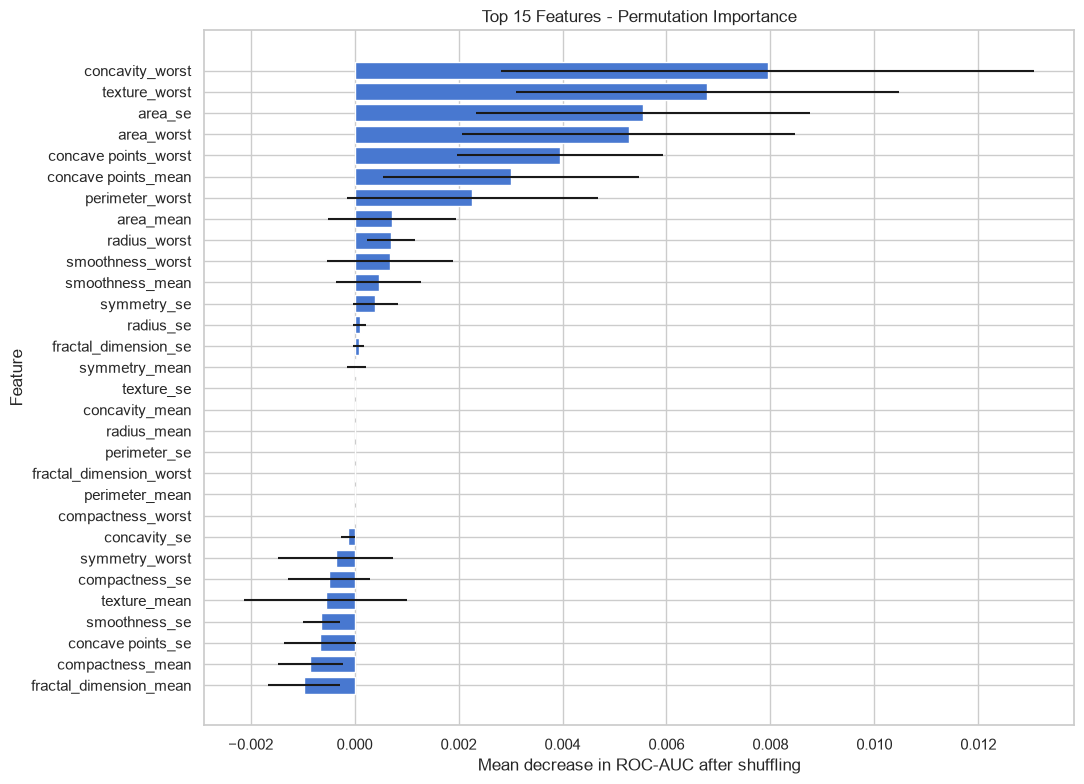

In [26]:
# Visualize the 15 features with the highest permutation importance
top_permutation_features = permutation_importance_df.sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(11, 8))
plt.barh(
    top_permutation_features['Feature'],
    top_permutation_features['Importance'],
    xerr=top_permutation_features['Std']
)
plt.title('Top 15 Features - Permutation Importance')
plt.xlabel('Mean decrease in ROC-AUC after shuffling')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**How to interpret this result:**

- Larger positive values indicate that shuffling the feature reduced ROC-AUC, suggesting that the model relies on it.
- Values close to zero suggest little measurable contribution in this model.
- Negative values mean that shuffling the feature improved ROC-AUC in these repetitions.

Because several measurements are correlated, importance can be shared across related features. A low individual score does not necessarily mean that the underlying measurement is useless.

## 3. Feature Correlation Analysis

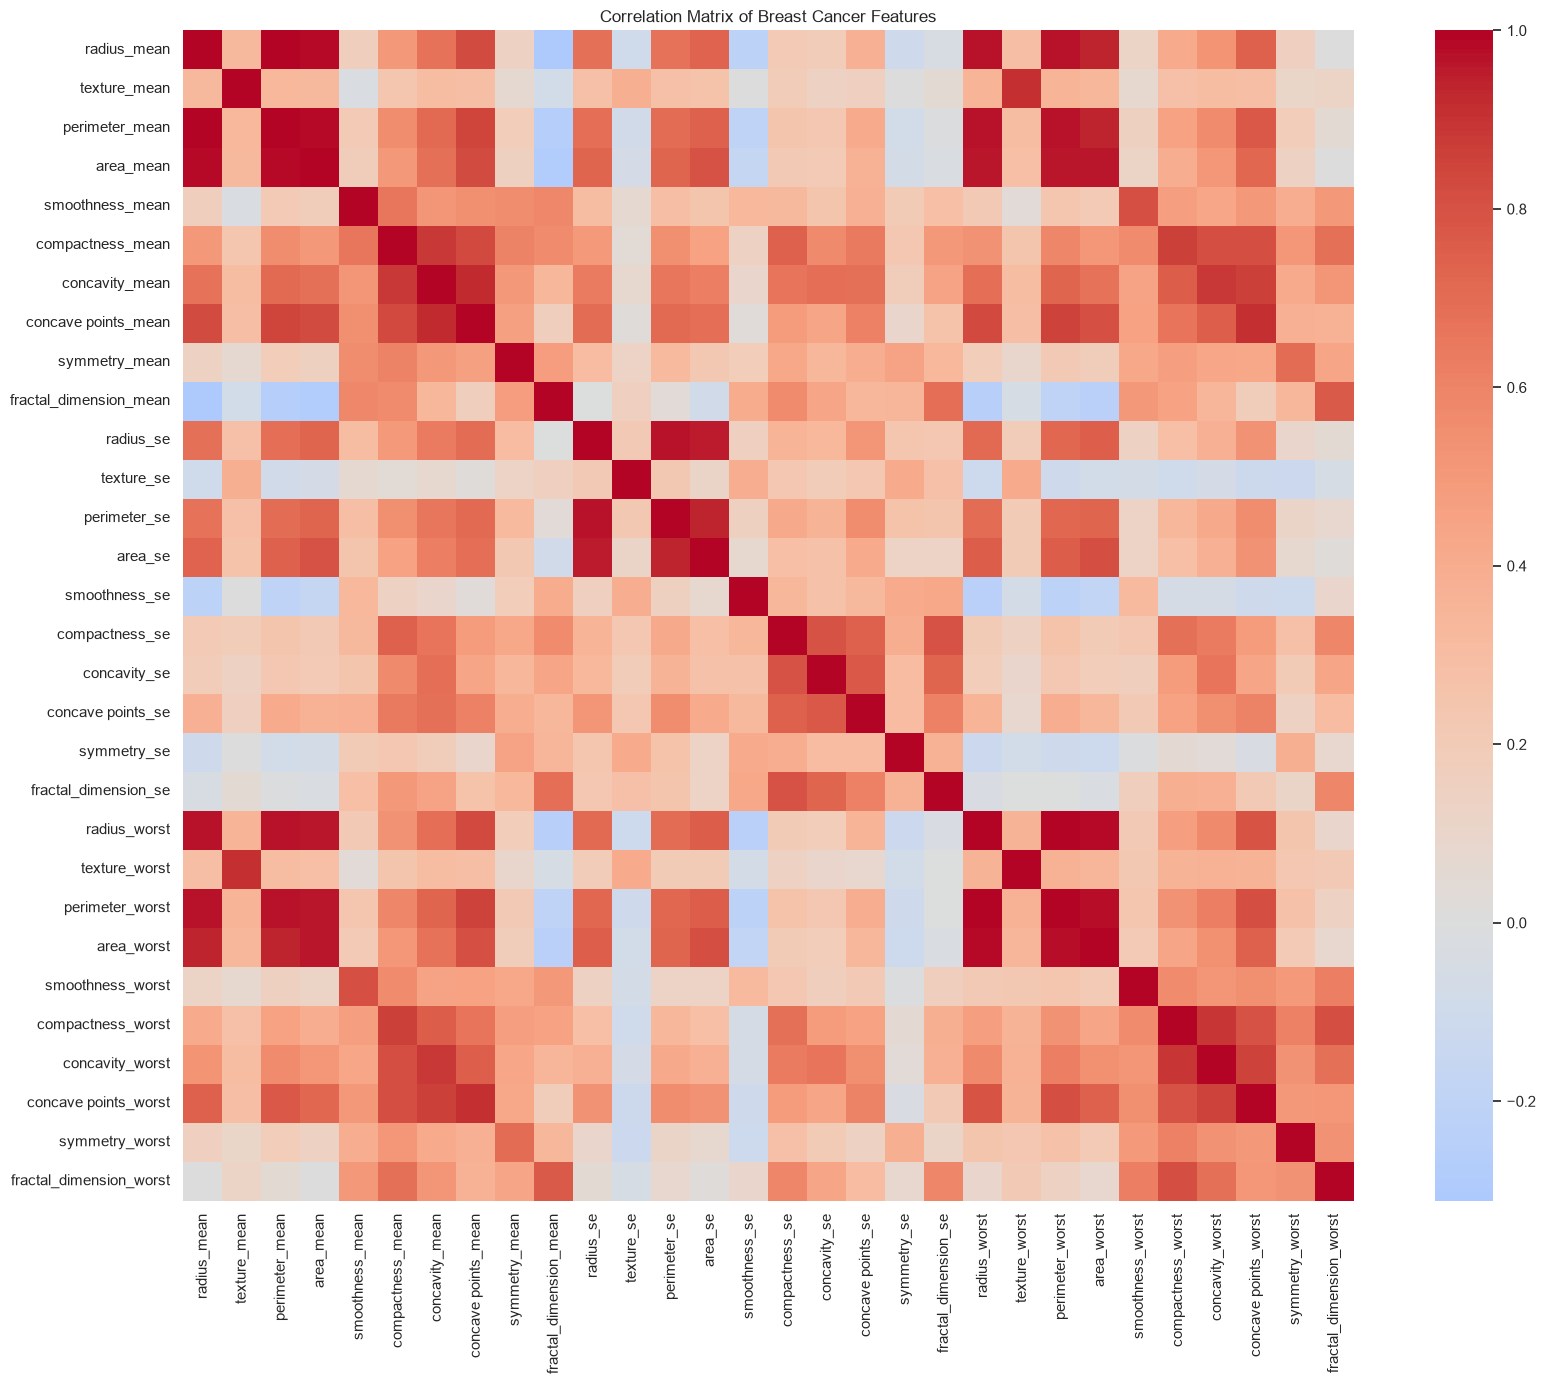

In [25]:
# Calculate correlations between the original predictive features
feature_df = df.loc[:, feature_names]
correlation_matrix = feature_df.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    square=True
)
plt.title('Correlation Matrix of Breast Cancer Features')
plt.tight_layout()
plt.show()

Highly correlated columns may contain overlapping information. For example, radius, perimeter, and area describe related aspects of nuclear size.

Permutation importance may divide predictive importance among correlated features, while Logistic Regression coefficients may become less stable. Consider these relationships before removing columns.

## 4. Important Notes

- `id` is excluded because it is an identifier, not a meaningful predictive measurement.
- `diagnosis` is the target variable and must not be included in the input features.
- `Unnamed: 32` is an empty column in this dataset and is removed during data cleaning.
- SMOTE is applied only to the training data. The test data remains unchanged to provide a more realistic evaluation.
- The scaler is fitted only on the training data and then applied to the test data.
- The test set is used here to report permutation importance. If you use feature importance to select features and repeatedly tune the model, use a separate validation set or cross-validation to avoid overfitting your final test evaluation.

This notebook is an educational machine-learning experiment, not a clinically validated diagnostic tool.